# Reconstruction wireframes: best, medium, worst

Compare three saved reconstructions with the **canonical cleaned RICO ground truth**, using colorful boxes for GUI elements.

The default is **Qwen3.5-9B / 4×4096 average pooling**. No Qwen3.5 reconstruction run using `4096_last` was present when this notebook was created. Change `RUN_NAME` below to inspect another run, including a future Qwen3.5 / `4096_last` run. No encoder, decoder, or embedding tensors need to be loaded.

**Selection:** rank native-valid predictions by the report's strict Average Bounds IoU; select the highest, a configurable upper-middle percentile (90th by default), and the lowest eligible entries. The upper-middle choice gives a more informative qualitative example than the statistical median because this run's IoU distribution is strongly concentrated near zero. Require at least five components in both trees by default to avoid trivial one-box screens. Ground truth and drawable predictions must exist. Ties use class accuracy, count agreement, then global RICO ID. These are illustrative examples within that subset, not a held-out benchmark. Invalid JSON is counted but not repaired or used for these three wireframes.

The report's IoU pairs components by depth-first order and only scores the shorter tree, so it can miss omissions or extra elements. Component counts and class accuracy are shown alongside it. Colors indicate element **types**, not a predicted-to-ground-truth correspondence.


In [8]:
from pathlib import Path
import json
import math
import re
import sys
import textwrap
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import pandas as pd
from PIL import Image
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository or a subdirectory.")
sys.path.insert(0, str(ROOT))
from utils import clean_screen, device_frame
from reconstruction_metrics import flatten_components

# Change this one value to select a different decoder / embedding run.
RUN_NAME = "reconstructions_4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b"
RUN_DIR = ROOT / RUN_NAME
DATA_DIRS = [ROOT.parent / "rico-data/data/layouts",
             ROOT / "data/rico-examples", ROOT / "rico/examples"]
MIN_COMPONENTS = 5
MIDDLE_PERCENTILE = 0.90  # stronger upper-middle example; must be between 0 and 1
SHOW_SCREENSHOTS = True
SHOW_LABELS = True
# Optional reproducible override, using global layout IDs (not report item indices).
SCREEN_IDS = None  # e.g. {"Best": 123, "Medium": 456, "Worst": 789}
EXPORT_DIR = ROOT / "overleaf/graphics/reconstruction_wireframes"

available_runs = sorted(p.name for p in ROOT.glob("reconstructions*") if p.is_dir())
if not RUN_DIR.is_dir():
    raise FileNotFoundError(f"{RUN_DIR}\nAvailable runs:\n" + "\n".join(available_runs))
print("Selected run:", RUN_NAME)
print("Available Qwen3.5 runs:")
print("\n".join(name for name in available_runs if "qwen3.5" in name))


Selected run: reconstructions_4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b
Available Qwen3.5 runs:
reconstructions_4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-2b
reconstructions_4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b


In [9]:
METRIC_LABELS = {
    "iou": "Average Bounds IoU",
    "class_accuracy": "Class Accuracy",
    "levenshtein": "Levenshtein Similarity (minified)",
    "gt_count": "Component Count (GT)",
    "pred_count": "Component Count (Pred)",
}

def parse_report(path):
    text = path.read_text(encoding="utf-8")
    # Anchor to full report lines so JSON text cannot be mistaken for metrics.
    def field(label):
        match = re.search(r"^" + re.escape(label) + r"\*?\s*:\s*([^\r\n]*)",
                          text, re.MULTILINE)
        return match[1].strip() if match else None

    source = field("JSON Path")
    embedding = field("Embedding Path")
    if not source or not embedding:
        return None  # failed generation / incomplete report
    # Old generators could name files by DataFrame index. Resolve the GLOBAL ID
    # from the report's source path, never from Item Index / report filename.
    screen_id = Path(source.replace("\\", "/")).stem
    embedding_id = Path(embedding.replace("\\", "/")).stem
    if not screen_id.isdigit() or embedding_id != screen_id:
        raise ValueError(f"Inconsistent source/embedding IDs in {path}")
    row = {
        "screen_id": int(screen_id), "report": path, "source": source,
        "prediction": path.with_name(path.name.replace("_report.txt", "_reconstructed.json")),
        "native_valid": field("JSON Valid") == "Yes",
    }
    for key, label in METRIC_LABELS.items():
        value = field(label)
        try:
            row[key] = float(value)
        except (TypeError, ValueError):
            return None
    return row

report_paths = sorted(RUN_DIR.glob("*_report.txt"))
if not report_paths:
    raise FileNotFoundError(f"No reports in {RUN_DIR}")
with ThreadPoolExecutor(max_workers=8) as pool:
    rows = list(pool.map(parse_report, report_paths))
reports = pd.DataFrame(row for row in rows if row is not None)
if reports.empty:
    raise ValueError("No complete reports with source paths and strict metrics found.")

eligible = reports.loc[
    reports.native_valid
    & (reports.gt_count >= MIN_COMPONENTS)
    & (reports.pred_count >= MIN_COMPONENTS)
].copy()
eligible["count_agreement"] = (
    eligible[["gt_count", "pred_count"]].min(axis=1)
    / eligible[["gt_count", "pred_count"]].max(axis=1)
)
eligible = eligible.sort_values(
    ["iou", "class_accuracy", "count_agreement", "screen_id"],
    ascending=[True, True, True, False],
).reset_index(drop=True)
if len(eligible) < 3:
    raise ValueError("Fewer than three eligible reports. Choose another run or lower MIN_COMPONENTS.")
eligible["rank_percentile"] = 100 * eligible.iou.rank(method="average", pct=True)

print(f"Scanned {len(report_paths):,} reports; {len(reports):,} complete.")
print(f"Native valid: {reports.native_valid.sum():,}; "
      f"invalid JSON: {(~reports.native_valid).sum():,}.")
print(f"Eligible before checking source/prediction files: {len(eligible):,}.")
display(eligible[["iou", "class_accuracy", "gt_count", "pred_count"]]
        .describe(percentiles=[0.05, 0.5, 0.95]).round(3))


Scanned 66,261 reports; 66,261 complete.
Native valid: 51,392; invalid JSON: 14,869.
Eligible before checking source/prediction files: 45,376.


,iou,class_accuracy,gt_count,pred_count
count,45376.000,45376.000,45376.000,45376.000
mean,0.171,0.308,21.386,25.395
std,0.254,0.298,17.313,20.989
min,0.000,0.000,5.000,5.000
5%,0.001,0.000,5.000,6.000
50%,0.072,0.222,16.000,19.000
95%,0.937,1.000,55.000,67.000
max,1.000,1.000,417.000,152.000


In [10]:
def drawable_components(screen):
    result = []
    for path, node in flatten_components(screen):
        if not isinstance(node, dict):
            continue
        bounds = node.get("bounds")
        if not isinstance(bounds, list) or len(bounds) != 4:
            continue
        if not all(isinstance(v, (int, float)) and not isinstance(v, bool)
                   and math.isfinite(v) for v in bounds):
            continue
        x1, y1, x2, y2 = bounds
        if x2 > x1 and y2 > y1:
            result.append((path, node, bounds))
    return result

def load_example(row):
    source = Path(row.source.replace("\\", "/"))
    candidates = [source if source.is_absolute() else ROOT / source]
    candidates += [directory / f"{row.screen_id}.json" for directory in DATA_DIRS]
    gt_path = next((p for p in candidates if p.is_file()), None)
    if gt_path is None:
        raise FileNotFoundError(f"Ground truth missing for global RICO ID {row.screen_id}")
    # Use the existing schema exactly; do not clean an already-cleaned prediction.
    gt = clean_screen(gt_path)
    pred = json.loads(row.prediction.read_text(encoding="utf-8"))
    if not isinstance(pred, dict) or not isinstance(pred.get("components"), list):
        raise ValueError("Prediction is not a cleaned screen object.")
    gt_boxes, pred_boxes = drawable_components(gt), drawable_components(pred)
    if not gt_boxes or not pred_boxes:
        raise ValueError("No positive-area, numeric boxes to draw.")
    raw = json.loads(gt_path.read_text(encoding="utf-8"))
    width, height = device_frame(raw["activity"]["root"])
    return dict(row=row, gt=gt, pred=pred, gt_path=gt_path,
                screenshot=gt_path.with_suffix(".jpg"), aspect=height / width)

selected, skipped, used = {}, [], set()
if not 0 <= MIDDLE_PERCENTILE <= 1:
    raise ValueError("MIDDLE_PERCENTILE must be between 0 and 1.")
middle = MIDDLE_PERCENTILE * (len(eligible) - 1)
orders = {
    "Best": list(reversed(eligible.index)),
    "Medium": sorted(eligible.index, key=lambda i: (abs(i - middle), i)),
    "Worst": list(eligible.index),
}
for label, indices in orders.items():
    if SCREEN_IDS is not None:
        indices = eligible.index[eligible.screen_id == SCREEN_IDS[label]].tolist()
    for index in indices:
        row = eligible.loc[index]
        if row.screen_id in used:
            continue
        try:
            example = load_example(row)
        except (OSError, ValueError, TypeError, KeyError, RecursionError) as exc:
            skipped.append((int(row.screen_id), str(exc)))
            continue
        selected[label] = example
        used.add(row.screen_id)
        break
    if label not in selected:
        raise ValueError(f"Could not load {label} example. Check paths / SCREEN_IDS. {skipped[-3:]}")

summary = pd.DataFrame([
    {"Example": label, "RICO ID": ex["row"].screen_id,
     "Strict IoU": ex["row"].iou, "IoU percentile": ex["row"].rank_percentile,
     "Class accuracy": ex["row"].class_accuracy,
     "GT components": len(flatten_components(ex["gt"])),
     "Pred components": len(flatten_components(ex["pred"])),
     "Levenshtein similarity": ex["row"].levenshtein,
     "GT app": ex["gt"].get("app"), "Pred app": ex["pred"].get("app")}
    for label, ex in selected.items()
]).set_index("Example")
display(summary.round(4))
if skipped:
    print(f"Skipped {len(skipped)} unavailable or undrawable candidates:", skipped[:5])
for label, ex in selected.items():
    print(f"{label}: {ex['gt_path']}\n  {ex['row'].prediction}")


,RICO ID,Strict IoU,IoU percentile,Class accuracy,GT components,Pred components,Levenshtein similarity,GT app,Pred app
Example,,,,,,,,,
Best,19,1.0000,98.1907,1.0,9,9,0.9050,com.android.browser,com.android.browser
Medium,23718,0.5099,89.9991,0.1,10,11,0.5863,com.zwigglers.android.horoscopes,com.riatech.salads
Worst,37668,0.0000,1.6859,0.0,24,70,0.2885,com.app.wooplr,com.fashionmerchants.mis


Best: C:\Users\Jonathan\Dev\screen2vec-revisited\..\rico-data\data\layouts\19.json
  C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructions_4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b\19_reconstructed.json
Medium: C:\Users\Jonathan\Dev\screen2vec-revisited\..\rico-data\data\layouts\23718.json
  C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructions_4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b\23718_reconstructed.json
Worst: C:\Users\Jonathan\Dev\screen2vec-revisited\..\rico-data\data\layouts\37668.json
  C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructions_4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b\37668_reconstructed.json


## Read the wireframes

Coordinates use the cleaner's **1–100 device-frame bins**, with the origin at the top left. Both wireframes use the ground-truth device aspect ratio. Parent containers have dashed outlines; children are drawn over them. Text is shortened for readability, and very small elements retain their boxes without labels. No geometry is repaired or rescaled to fit a prediction; out-of-frame boxes are clipped at the display boundary and counted below the figure.

The screenshot is optional context. Wireframes visualize the cleaned hierarchy, which can represent an entire WebView as one component even when the screenshot has many visible controls.


**BEST | RICO 19 | Strict IoU 1.000 | Class accuracy 1.000**

4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b | GT: 9 boxes; 0 non-drawable; 0 out-of-frame | Prediction: 9 boxes; 0 non-drawable; 0 out-of-frame

Saved to C:\Users\Jonathan\Dev\screen2vec-revisited\overleaf\graphics\reconstruction_wireframes\best_19.pdf


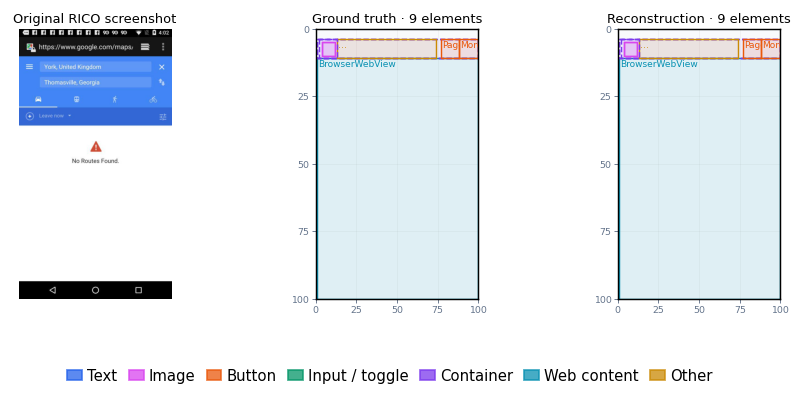

**Best - screen 19.** Ground truth: `com.android.browser` / `BrowserActivity`. Prediction: `com.android.browser` / `BrowserActivity`.

**MEDIUM | RICO 23718 | Strict IoU 0.510 | Class accuracy 0.100**

4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b | GT: 10 boxes; 0 non-drawable; 0 out-of-frame | Prediction: 11 boxes; 0 non-drawable; 0 out-of-frame

Saved to C:\Users\Jonathan\Dev\screen2vec-revisited\overleaf\graphics\reconstruction_wireframes\medium_23718.pdf


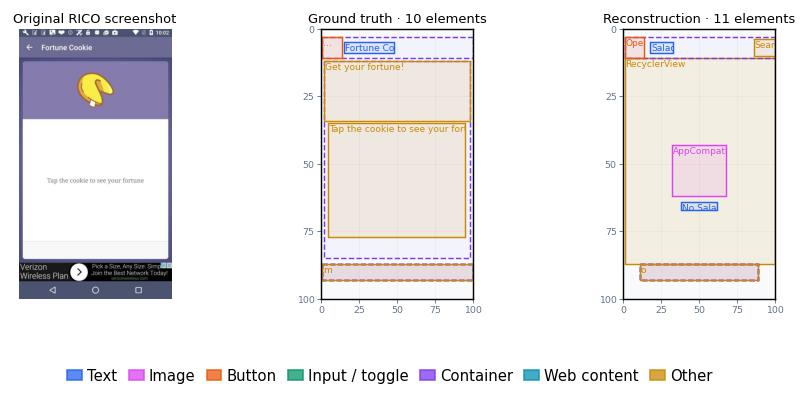

**Medium - screen 23718.** Ground truth: `com.zwigglers.android.horoscopes` / `FortuneActivity`. Prediction: `com.riatech.salads` / `MainActivity`.

**WORST | RICO 37668 | Strict IoU 0.000 | Class accuracy 0.000**

4x4096_avg__via__embeddings_4x4096_avg_full_qwen3.5-9b | GT: 24 boxes; 0 non-drawable; 0 out-of-frame | Prediction: 70 boxes; 0 non-drawable; 0 out-of-frame

Saved to C:\Users\Jonathan\Dev\screen2vec-revisited\overleaf\graphics\reconstruction_wireframes\worst_37668.pdf


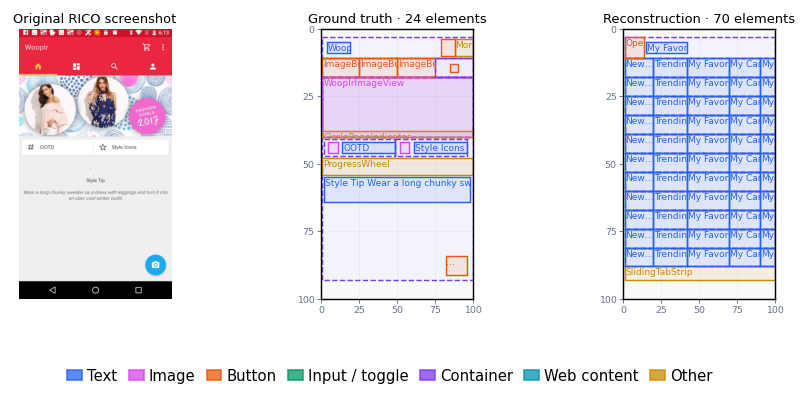

**Worst - screen 37668.** Ground truth: `com.app.wooplr` / `MainActivity`. Prediction: `com.fashionmerchants.mis` / `MainActivity`.

In [20]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image
from IPython.display import display, Markdown


PALETTE = {
    "Text": "#2563eb",
    "Image": "#d946ef",
    "Button": "#ea580c",
    "Input / toggle": "#059669",
    "Container": "#7c3aed",
    "Web content": "#0891b2",
    "Other": "#ca8a04",
}

CM_TO_INCH = 1 / 2.54
FIGURE_WIDTH_CM = 17.8
FIGURE_HEIGHT_CM = 8


def element_type(node):
    name = str(node.get("class", "")).rsplit(".", 1)[-1].lower()
    if any(s in name for s in ("edittext", "checkbox", "switch", "radio", "seekbar", "spinner")):
        return "Input / toggle"
    if "button" in name:
        return "Button"
    if "image" in name:
        return "Image"
    if "text" in name:
        return "Text"
    if "webview" in name:
        return "Web content"
    if node.get("children") or any(s in name for s in ("layout", "toolbar", "list", "grid", "card")):
        return "Container"
    return "Other"


def draw_wireframe(ax, screen, aspect, title):
    ax.set(xlim=(0, 100), ylim=(100, 0), title=title)
    ax.set_aspect(aspect)
    ax.set_facecolor("#f8fafc")
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.tick_params(
        labelsize=5.2,
        colors="#64748b",
        pad=1.5,
        length=2.0,
        width=0.5,
    )
    ax.grid(alpha=0.15, linewidth=0.4)

    boxes = drawable_components(screen)
    boxes = sorted(
        boxes,
        key=lambda item: (item[2][2] - item[2][0]) * (item[2][3] - item[2][1]),
        reverse=True,
    )

    outside = 0
    for path, node, (x1, y1, x2, y2) in boxes:
        color = PALETTE[element_type(node)]
        container = bool(node.get("children"))
        outside += int(x1 < 0 or y1 < 0 or x2 > 100 or y2 > 100)

        rect = Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            facecolor=(
                *plt.matplotlib.colors.to_rgb(color),
                0.035 if container else 0.10,
            ),
            edgecolor=color,
            linewidth=0.8,
            linestyle="--" if container else "-",
            zorder=2,
        )
        ax.add_patch(rect)

        if SHOW_LABELS and not container and x2 - x1 >= 10 and y2 - y1 >= 2:
            label = (
                node.get("text")
                or node.get("content-desc")
                or str(node.get("class", "?")).rsplit(".", 1)[-1]
            )
            max_chars = max(4, int((x2 - x1) / 2.0))
            label = textwrap.shorten(
                " ".join(str(label).split()),
                width=max_chars,
                placeholder="…",
            )
            artist = ax.text(
                x1 + 0.6,
                y1 + 0.5,
                label,
                fontsize=5.0,
                va="top",
                color=color,
                clip_on=True,
                zorder=3,
            )
            artist.set_clip_path(rect)

    omitted = len(flatten_components(screen)) - len(boxes)
    return f"{len(boxes)} boxes; {omitted} non-drawable; {outside} out-of-frame"


plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.dpi": 130,
    "axes.titlesize": 7.2,
    "axes.titlepad": 3.5,
})


for label, ex in selected.items():
    row = ex["row"]
    gt = ex["gt"]
    pred = ex["pred"]
    ncols = 3 if SHOW_SCREENSHOTS else 2

    fig, axes = plt.subplots(
        1,
        ncols,
        figsize=(
            FIGURE_WIDTH_CM * CM_TO_INCH,
            FIGURE_HEIGHT_CM * CM_TO_INCH,
        ),
    )

    if ncols == 1:
        axes = [axes]

    if SHOW_SCREENSHOTS:
        axes[0].set_title("Original RICO screenshot")
        axes[0].axis("off")
        if ex["screenshot"].is_file():
            with Image.open(ex["screenshot"]) as screenshot:
                axes[0].imshow(screenshot.copy())
        else:
            axes[0].text(
                0.5,
                0.5,
                "Screenshot unavailable",
                ha="center",
                va="center",
                fontsize=6.0,
            )

    gt_note = draw_wireframe(
        axes[-2],
        gt,
        ex["aspect"],
        f"Ground truth · {len(flatten_components(gt))} elements",
    )

    pred_note = draw_wireframe(
        axes[-1],
        pred,
        ex["aspect"],
        f"Reconstruction · {len(flatten_components(pred))} elements",
    )

    run_name = RUN_NAME.removeprefix("reconstructions_")

    notebook_title = (
        f"{label.upper()} | RICO {row.screen_id} | "
        f"Strict IoU {row.iou:.3f} | "
        f"Class accuracy {row.class_accuracy:.3f}"
    )

    notebook_note = (
        f"{run_name} | GT: {gt_note} | Prediction: {pred_note}"
    )

    display(Markdown(f"**{notebook_title}**"))
    display(Markdown(notebook_note))

    legend = [
        Patch(
            facecolor=color,
            edgecolor=color,
            alpha=0.75,
            label=name,
        )
        for name, color in PALETTE.items()
    ]

    fig.legend(
        handles=legend,
        loc="lower center",
        ncol=len(PALETTE),
        frameon=False,
        fontsize=8.25,
        bbox_to_anchor=(0.5, 0.02),
        handlelength=1.0,
        handletextpad=0.35,
        columnspacing=0.75,
        borderaxespad=0.0,
    )

    fig.subplots_adjust(
        left=0.025,
        right=0.99,
        top=0.90,
        bottom=0.24,
        wspace=0.10,
    )

    if EXPORT_DIR is not None:
        Path(EXPORT_DIR).mkdir(parents=True, exist_ok=True)
        output_path = Path(EXPORT_DIR) / f"{label.lower()}_{row.screen_id}.pdf"
        fig.savefig(
            output_path,
        )
        print("Saved to", output_path)

    plt.show()
    plt.close(fig)

    display(Markdown(
        f"**{label} - screen {row.screen_id}.** "
        f"Ground truth: `{gt.get('app', '')}` / `{gt.get('activity', '')}`. "
        f"Prediction: `{pred.get('app', '')}` / `{pred.get('activity', '')}`."
    ))

To inspect full labels or hierarchy paths, run the optional cell below. `selected["Best"]["gt"]` and `selected["Best"]["pred"]` also expose the complete cleaned objects in memory.

In [12]:
def component_table(screen):
    return pd.DataFrame([
        {"path": path, "class": node.get("class"), "text": node.get("text", ""),
         "content-desc": node.get("content-desc", ""), "bounds": node.get("bounds")}
        for path, node in flatten_components(screen) if isinstance(node, dict)
    ])

# Uncomment to inspect an example without truncating labels in the plot.
display(component_table(selected["Medium"]["gt"]))
display(component_table(selected["Medium"]["pred"]))


,path,class,text,content-desc,bounds
0,/0,android.support.v7.widget.Toolbar,,,"[1, 3, 100, 11]"
1,/0/0,android.widget.TextView,Fortune Cookie,,"[15, 5, 48, 9]"
2,/0/1,android.widget.ImageButton,,Navigate up,"[1, 3, 14, 11]"
3,/1,android.support.v7.widget.CardView,,,"[2, 12, 98, 85]"
4,/1/0,android.support.v7.widget.o,,Get your fortune!,"[2, 12, 98, 34]"
5,/1/1,android.support.v7.widget.ab,Tap the cookie to see your fortune,,"[5, 35, 95, 77]"
6,/2,com.google.android.gms.ads.AdView,,,"[1, 87, 100, 93]"
7,/2/0,com.google.android.gms.ads.internal.bi,,,"[1, 87, 100, 93]"
8,/2/0/0,com.google.android.gms.ads.internal.webview.l,,,"[1, 87, 100, 93]"
9,/2/0/0/0,com.google.android.gms.ads.internal.webview.m,,,"[1, 87, 100, 93]"


,path,class,text,content-desc,bounds
0,/0,android.support.v7.widget.Toolbar,,,"[1, 3, 100, 11]"
1,/0/0,android.support.v7.widget.AppCompatTextView,Salads,,"[18, 5, 33, 9]"
2,/0/1,android.support.v7.widget.AppCompatImageButton,,Open,"[1, 3, 14, 11]"
3,/0/2,android.support.v7.view.menu.ActionMenuItemView,,Search for recipes,"[86, 4, 100, 10]"
4,/1,android.support.v7.widget.RecyclerView,,,"[1, 11, 100, 87]"
5,/2,com.google.android.gms.ads.AdView,,,"[11, 87, 89, 93]"
6,/2/0,com.google.android.gms.ads.internal.bp,,,"[11, 87, 89, 93]"
7,/2/0/0,com.google.android.gms.ads.internal.webview.n,,,"[11, 87, 89, 93]"
8,/2/0/0/0,com.google.android.gms.ads.internal.webview.o,,,"[11, 87, 89, 93]"
9,/3,android.support.v7.widget.AppCompatImageView,,,"[32, 43, 68, 62]"
